# 8-2. 생성형 AI를 활용한 제조결함 데이터 생성 실습

AnomalyAny에 정상 이미지와 결함 설명을 입력해 결함 이미지를 생성한다. 탁자의 변색, 헤이즐넛의 균열, PCB의 균열을 실습한 뒤, PCB에서 원본 구조를 유지하면서 균열을 표현하는 조건을 비교한다.

진행 순서는 환경 준비 → 모델과 공통 함수 준비 → 기본 생성 결과 확인 → 입력 이미지 조건값 비교 → 상세 프롬프트 변경 → 마스크 적용 → 마스크 적용 상태의 조건값 비교이다.

기존 실행 이미지와 로그를 유지하면서 코드를 기능별로 나눴다. 실행 번호는 분할 전 셀의 실행 기록이며, 재실행할 때는 위에서 아래로 진행한다.

출처: EPFL-IMOS의 [AnomalyAny GitHub 저장소](https://github.com/EPFL-IMOS/AnomalyAny).

## 1. 저장소와 실행 환경 준비

AnomalyAny 저장소를 복제하고 작업 폴더로 이동한다. 기존 코드가 사용하는 API에 맞춰 Diffusers, Transformers, Hugging Face Hub와 연동 패키지의 버전을 지정하고, OpenAI CLIP 등을 설치한다.

`os.chdir('AnomalyAny')`는 현재 위치에서 상대 경로로 이동한다. 현재 경로 출력으로 저장소 안에 있는지 확인한다. 뒤의 `normal.png`도 이 작업 폴더를 기준으로 읽는다.

In [ ]:
!git clone https://github.com/EPFL-IMOS/AnomalyAny

Cloning into 'AnomalyAny'...
remote: Enumerating objects: 87, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 87 (delta 26), reused 19 (delta 19), pack-reused 53 (from 1)
Receiving objects: 100% (87/87), 17.84 MiB | 7.62 MiB/s, done.
Resolving deltas: 100% (29/29), done.


In [ ]:
import os
os.chdir('AnomalyAny')
print("현재 디렉토리:", os.getcwd())

현재 디렉토리: /content/AnomalyAny/AnomalyAny


In [ ]:
%pip install \
    "diffusers==0.33.1" \
    "transformers==4.52.4" \
    "huggingface_hub==0.33.4" \
    "tokenizers==0.21.4" \
    "accelerate==1.7.0" \
    "peft==0.15.2" \
    "pyrallis==0.3.1" \
    numpy Pillow matplotlib opencv-python ipython packaging \
    git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-7ft_nbwb
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-7ft_nbwb
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done


### 공통 라이브러리와 프로젝트 함수 불러오기

프로젝트의 생성 파이프라인, 설정 객체, 실행 함수와 attention 시각화 기능을 불러온다. `sys.path`에는 현재 폴더와 상위 폴더를 추가한다. `autoreload` 명령은 주석 상태이며 실행하지 않는다.

In [ ]:
from typing import List, Dict
import torch

import sys
sys.path.append(".")
sys.path.append("..")

from clip_pipeline_attend_and_excite import RelationalAttendAndExcitePipeline
from config import RunConfig
from run import run_on_prompt, get_indices_to_alter, run_on_prompt_and_image, run_on_prompt_and_masked_image
from utils import vis_utils
from utils.ptp_utils import AttentionStore, show_cross_attention_binary

from utils.vis_utils import vis_ann

from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

#%load_ext autoreload
#%autoreload 2

## 2. 사전학습 모델 준비

Stable Diffusion v1.5 기반의 `RelationalAttendAndExcitePipeline`을 불러오고 tokenizer를 준비한다. 생성 스텝 설정은 200, guidance scale은 12.5이며, 이후 실험에서 같은 모델을 재사용한다.

뒤에서 비교하는 `init_image_guidance_scale`은 입력 이미지에 노이즈를 더하는 수준과 사용할 확산 구간에 관여한다. 값을 높이면 원본에서 더 크게 달라질 수 있다.

In [ ]:
NUM_DIFFUSION_STEPS = 200
GUIDANCE_SCALE = 12.5
MAX_NUM_WORDS = 77
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
stable = RelationalAttendAndExcitePipeline.from_pretrained("runwayml/stable-diffusion-v1-5", safety_checker=None).to(device)
tokenizer = stable.tokenizer

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'clip_pipeline_attend_and_excite.RelationalAttendAndExcitePipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


## 3. 탁자 입력과 공통 생성 함수 준비

### 입력 이미지와 세 종류의 프롬프트

`example_web/table.jpg`를 RGB로 읽고, 가로·세로 최대 768 범위로 축소한다.

| 변수 | 역할 | 탁자 예제 |
|---|---|---|
| `prompt` | 생성할 결함을 포함한 기본 설명 | 색이 바랜 탁자 |
| `normal_prompt` | 정상 상태의 설명 | 탁자 |
| `detailed_prompt` | 결함 상태를 구체화한 설명 | 햇빛에 오래 노출돼 변색되거나 밝아진 탁자 |

`tokens="8"`은 강조할 `faded`의 토큰 위치이다. 생성 전 토큰 선택 출력으로 해당 단어가 선택됐는지 확인한다.

In [ ]:
from PIL import Image

type = "table"
tokens = "8"
prompt = f"a photo of a {type} that is faded"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with areas of discoloration or lightening due to prolonged sun exposure"

root_path = f"./example_web/"
image_guidance_path = root_path + "table.jpg"


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

### 공통 생성 함수

`run_and_display`는 생성 조건을 `RunConfig`에 모아 입력 이미지, 프롬프트, 강조할 토큰, controller와 generator를 생성 함수에 전달한다. 생성 이미지와 latent를 반환하며 `display_output=True`이면 이미지를 표시한다.

함수 기본 인자의 `normal_prompt`와 `detailed_prompt`는 정의 시점의 탁자 설명을 사용한다. 뒤의 헤이즐넛과 PCB 호출에서는 각 대상의 설명을 명시적으로 전달한다.

In [ ]:
def run_and_display(prompts: List[str],
                    controller: AttentionStore,
                    indices_to_alter: List[int],
                    init_image: Image.Image,
                    init_image_guidance_scale: float,
                    mask_image: str,
                    generator: torch.Generator,
                    run_standard_sd: bool = False,
                    scale_factor: int = 20,
                    thresholds: Dict[int, float] = {0: 0.05, 10: 0.5, 20: 0.8},
                    max_iter_to_alter: int = 25,
                    display_output: bool = False,
                    normal_prompt=normal_prompt,
                    detailed_prompt=detailed_prompt):
    config = RunConfig(prompt=prompts[0],
                       run_standard_sd=run_standard_sd,
                       scale_factor=scale_factor,
                       thresholds=thresholds,
                       max_iter_to_alter=max_iter_to_alter,
                       n_inference_steps=NUM_DIFFUSION_STEPS,
                       guidance_scale=GUIDANCE_SCALE)
    image, image_latent = run_on_prompt_and_masked_image(model=stable,
                          prompt=prompts,
                          controller=controller,
                          token_indices=indices_to_alter,
                          init_image=init_image,
                          init_image_guidance_scale=init_image_guidance_scale,
                          mask_image=mask_image,
                          seed=generator,
                          config=config,
                          normal_prompt=normal_prompt,
                          detailed_prompt=detailed_prompt)
    if display_output:
        display(image)
    return image, image_latent

## 4. 기본 생성 1: 탁자의 변색

### 시드와 강조할 토큰 준비

난수 시드 하나를 만들고, 기본 프롬프트에서 `faded`를 선택한다. `run_standard_sd=False`로 AnomalyAny의 생성 방식을 사용한다.

In [ ]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []


{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'table',
 6: 'that',
 7: 'is',
 8: 'faded'}
Altering tokens: ['faded']


### 이미지 생성과 attention 표시

각 시드마다 generator와 attention controller를 새로 만들고, 조건값 0.3, `scale_factor=50`, 마스크 없음으로 생성한다. 생성 이미지와 강조한 토큰의 attention을 표시하고, 처리 시간을 `compute_time`에 기록한다.

/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

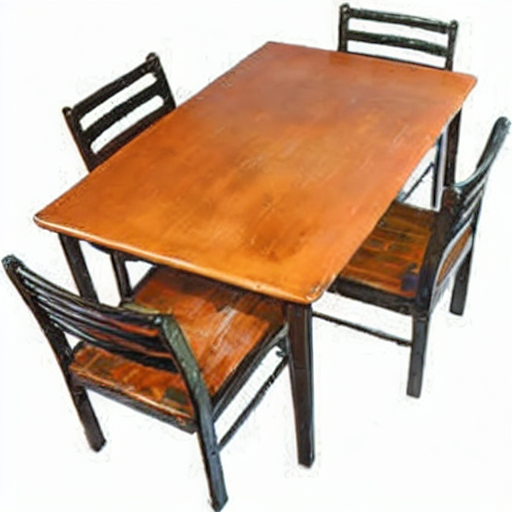

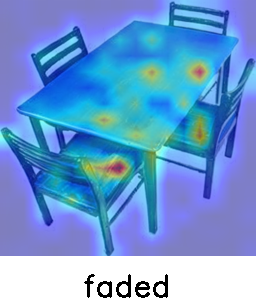

In [ ]:
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

### 토큰별 attention 확인

직전 생성에서 기록한 attention을 토큰별로 이진화해 표시한다. 결함을 설명하는 단어에 대응하는 attention이 이미지의 어느 부분에 나타나는지 살펴본다.

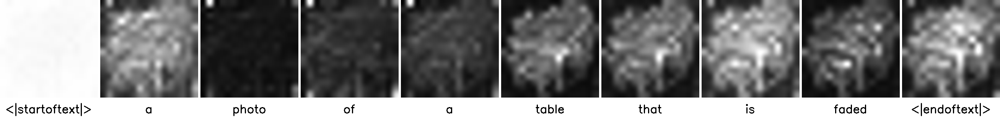

In [ ]:
images, attention_maps = show_cross_attention_binary(controller, tokenizer, prompts, res=16, from_where=("up", "mid", "down"))

## 5. 기본 생성 2: 헤이즐넛의 균열

### 입력과 생성 조건 준비

입력을 `example_image/000.png`로 바꾸고 균열을 요청한다. 기본 프롬프트에서는 `crack`을 강조하고, 상세 설명에는 내부가 드러나는 크고 거친 균열을 지정한다. 서로 다른 난수 시드 네 개로 결과를 비교한다.

In [ ]:
from PIL import Image

type = "hazelnut"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_num = str('000')
root_path = f"./example_image/"
image_guidance_path = root_path + image_num + '.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

In [ ]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []


{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'hazelnut',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


### 이미지 생성과 attention 표시

각 시드마다 generator와 attention controller를 새로 만들고, 조건값 0.3, `scale_factor=50`, 마스크 없음으로 생성한다. 생성 이미지와 강조한 토큰의 attention을 표시하고, 처리 시간을 `compute_time`에 기록한다.

/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

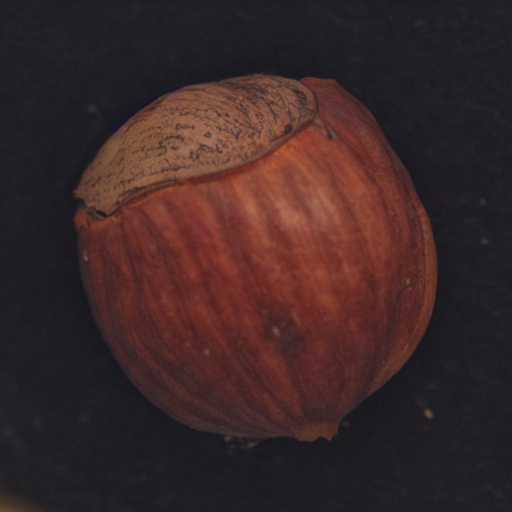

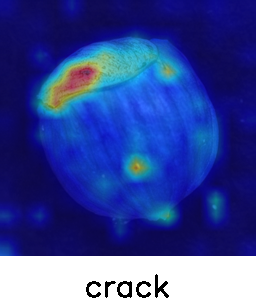

  0%|          | 0/200 [00:00<?, ?it/s]

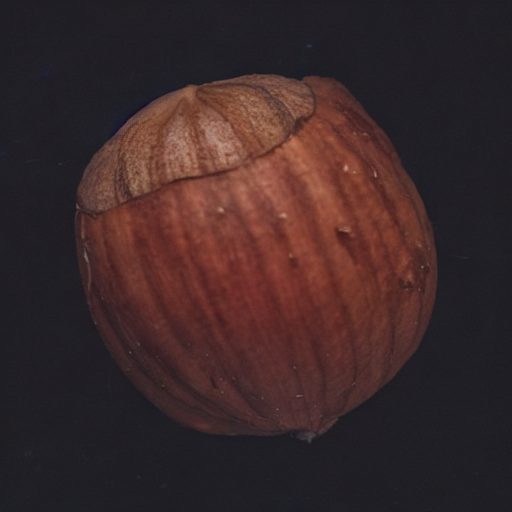

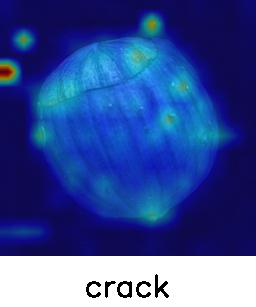

  0%|          | 0/200 [00:00<?, ?it/s]

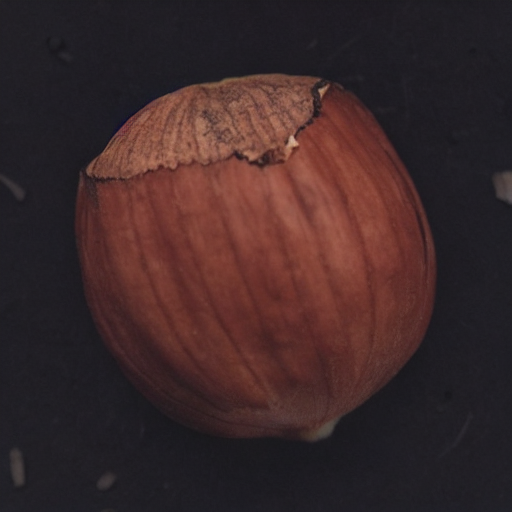

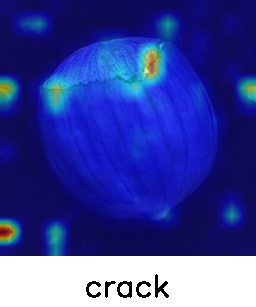

  0%|          | 0/200 [00:00<?, ?it/s]

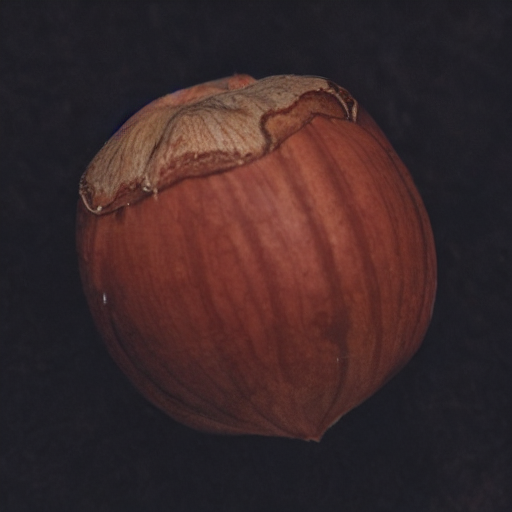

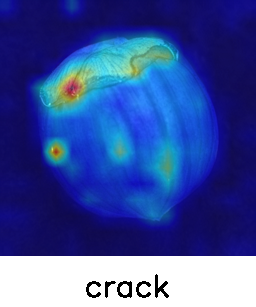

In [ ]:
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

## 6. 기본 생성 3: PCB의 균열

### 정상 PCB와 결함 설명 준비

현재 작업 폴더의 `normal.png`를 RGB로 읽어 사용한다. 기본 설명은 `a photo of a pcb with a crack on it`이며, `crack`을 강조한다. 상세 설명에는 내부가 드러나는 크고 거친 균열을 지정한다.

Drive 연결 셀도 유지했다. 이미지 입력 경로는 Drive 경로가 아니라 현재 작업 폴더의 `normal.png`이다. 서로 다른 난수 시드 네 개에서 기판 형태, 부품 배치와 균열 표현을 확인한다.

In [ ]:
from PIL import Image

type = "pcb"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_guidance_path = 'normal.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
image_guidance.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []


{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


### 이미지 생성과 attention 표시

각 시드마다 generator와 attention controller를 새로 만들고, 조건값 0.3, `scale_factor=50`, 마스크 없음으로 생성한다. 생성 이미지와 강조한 토큰의 attention을 표시하고, 처리 시간을 `compute_time`에 기록한다.

/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

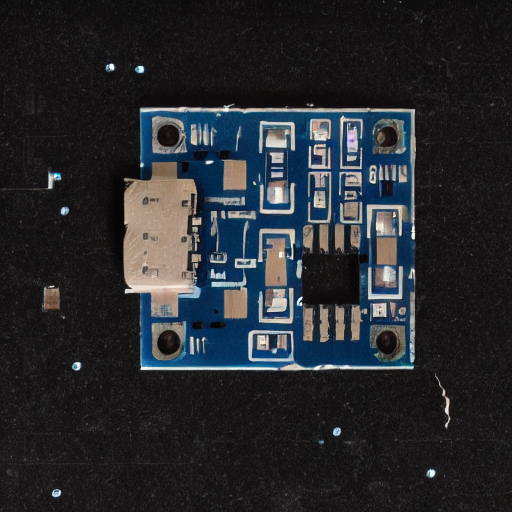

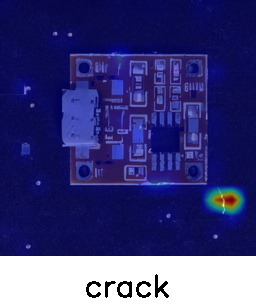

  0%|          | 0/200 [00:00<?, ?it/s]

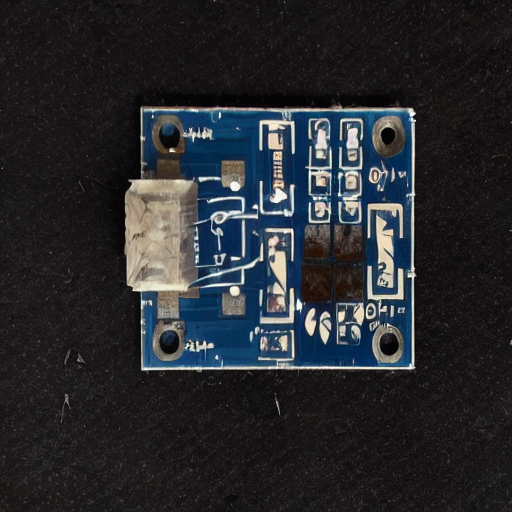

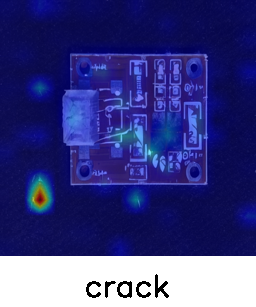

  0%|          | 0/200 [00:00<?, ?it/s]

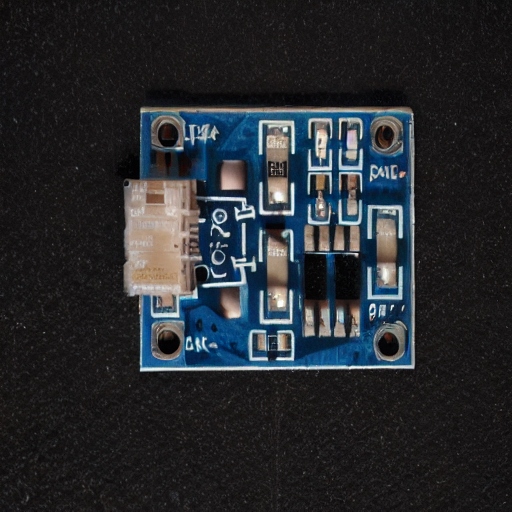

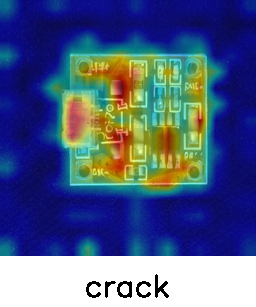

  0%|          | 0/200 [00:00<?, ?it/s]

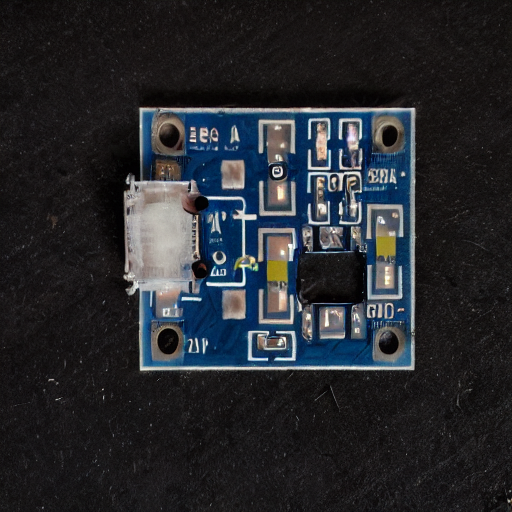

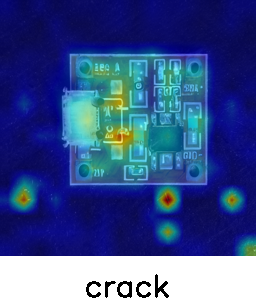

In [ ]:
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

## 7. 기본 결과 분석과 추가 실험 1 설계

### 기본 생성 결과

| 대상과 목표 | 관찰한 결과 |
|---|---|
| 햇빛 노출에 따른 탁자의 변색 | 상판에 밝기와 색이 고르지 않은 부분이 나타났지만, 햇빛에 의한 퇴색이 뚜렷하게 드러나지는 않았다. |
| 헤이즐넛의 깊고 거친 균열 | 껍질 윗부분의 경계와 갈라짐이 시드별로 달랐다. 일부 가장자리가 벌어지거나 벗겨진 모습은 나타났지만, 내부가 드러나는 깊은 균열은 명확하지 않았다. |
| PCB의 균열 | 부품·배선·커넥터와 일부 배경이 변했지만, 기판을 가르는 균열은 뚜렷하지 않았다. |

추가 실험에서는 PCB에 집중한다. 부품이나 배선의 형태만 달라지는 문제를 줄이고, 정상 구조를 유지하면서 균열을 표현할 수 있는지 확인한다.

### 추가 실험 1 계획: 입력 이미지 조건값 비교

조건값이 낮으면 원본이 유지되는 대신 결함 변화가 부족하고, 높으면 결함과 함께 원본 구조도 크게 변할 수 있다고 예상했다.

| 항목 | 설정 |
|---|---|
| 변경 조건 | `init_image_guidance_scale`: 0.1, 0.3, 0.5 |
| 공통 시드 | 42, 123, 2026 |
| 고정 조건 | 정상 PCB, 기본·정상·상세 프롬프트, 마스크 없음, 생성 스텝 설정 200, guidance scale 12.5, scale_factor 50 |
| 생성 수 | 3개 조건 × 3개 시드 = 9장 |
| 비교 기준 | 균열의 명확성, 기판·부품·배선의 보존, 배경 변화 |

같은 시드끼리 조건값에 따른 결과를 비교한다.

### 비교 조건 준비

기존 PCB 이미지와 함수를 재사용하고, 조건값 목록과 공통 시드를 지정한다. 프롬프트에서 강조할 `crack`의 토큰 위치도 확인한다.

In [ ]:
import matplotlib.pyplot as plt

exp_values = [0.1, 0.3, 0.5]
exp_seeds = [42, 123, 2026]
exp_indices = get_indices_to_alter_new(stable, prompt, tokens)



### 조건별 생성과 비교표 출력

각 조건과 시드 조합에서 generator와 attention controller를 새로 만든다. 비교표의 행은 조건값, 같은 열은 같은 시드이다. 맨 왼쪽에는 원본을 표시한다. 생성과 그림 표시는 한 셀에서 실행하며, 다음 실험에서 이 비교표의 이미지를 재사용한다.

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']
설정값: 0.1, 시드: 42


  0%|          | 0/200 [00:00<?, ?it/s]

설정값: 0.1, 시드: 123


  0%|          | 0/200 [00:00<?, ?it/s]

설정값: 0.1, 시드: 2026


...

  0%|          | 0/200 [00:00<?, ?it/s]

설정값: 0.5, 시드: 123


  0%|          | 0/200 [00:00<?, ?it/s]

설정값: 0.5, 시드: 2026


  0%|          | 0/200 [00:00<?, ?it/s]

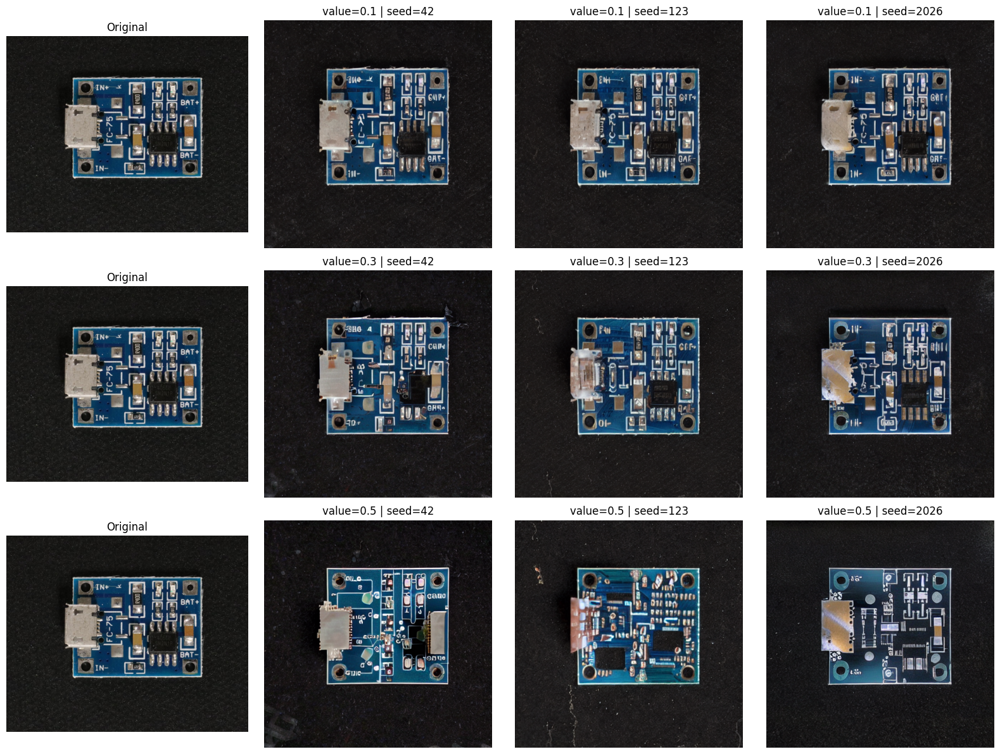

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row, exp_value in enumerate(exp_values):
    axes[row, 0].imshow(image_guidance)
    axes[row, 0].set_title("Original")
    axes[row, 0].axis("off")

    for col, exp_seed in enumerate(exp_seeds, start=1):
        print(f"설정값: {exp_value}, 시드: {exp_seed}")

        exp_generator = torch.Generator(
            device=stable.device
        ).manual_seed(exp_seed)
        exp_controller = AttentionStore()

        exp_image, _ = run_and_display(
            prompts=[prompt],
            controller=exp_controller,
            indices_to_alter=exp_indices,
            init_image=image_guidance.copy(),
            init_image_guidance_scale=exp_value,
            mask_image=None,
            generator=exp_generator,
            run_standard_sd=False,
            display_output=False,
            scale_factor=50,
            normal_prompt=normal_prompt,
            detailed_prompt=detailed_prompt,
        )

        axes[row, col].imshow(exp_image)
        axes[row, col].set_title(
            f"value={exp_value} | seed={exp_seed}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## 8. 추가 실험 1 결과 분석과 추가 실험 2 설계

### 조건값 비교 결과

| 조건값 | 균열 표현 | 원본 보존 |
|---|---|---|
| 0.1 | 세 시드 모두 뚜렷한 균열이 보이지 않았다. | 전체 구조는 비교적 유지됐지만 커넥터·문자·부품의 세부 표현이 달라졌다. |
| 0.3 | 커넥터와 회로가 변했지만 기판을 가르는 균열은 나타나지 않았다. | 부품과 배선 변화가 커졌고, 일부 결과에서는 기판 위쪽 배경에 검은 흔적이 생겼다. |
| 0.5 | 변화가 커져도 균열이 명확해지지는 않았다. | 부품 배치와 기판 내부 형태가 크게 달라졌다. |

조건값을 높이면 원본 구조의 변화가 커졌지만 균열 표현은 개선되지 않았다. 다음에는 조건값을 0.3으로 두고 결함 설명의 구체성을 바꾼다.

### 추가 실험 2 계획: 상세 프롬프트 변경

기존 설명은 대상의 재료나 회로 특성을 충분히 드러내지 않는다. PCB의 기판과 구리 배선에 발생한 균열을 구체적으로 설명하면 결함 표현이 나아지는지 비교한다.

| 항목 | 설정 |
|---|---|
| 변경 조건 | `detailed_prompt` |
| 기존 설명 | 내부가 드러나는 크고 거친 균열 |
| 새 설명 | 파란 PCB 기판을 가르는 깊고 거친 균열과 주변의 끊어진 구리 배선 |
| 고정 조건 | 입력 PCB, 기본·정상 프롬프트, crack 토큰, 조건값 0.3, 시드 42·123·2026, 나머지 생성 설정 |
| 생성 수 | 새 설명으로 3장. 기존 0.3 결과는 재사용 |
| 비교 기준 | 균열 표현의 개선, 기판·부품·배선 보존 |

기본 `prompt`는 유지하므로 `crack`의 토큰 위치도 그대로 사용한다.

### 새 상세 설명과 기준 이미지 준비

새 설명을 `exp2_detailed_prompt`에 저장하고, 이전 비교표의 0.3 행에서 같은 시드의 이미지를 가져온다. 앞선 실험에서 만든 `axes` 변수를 사용하므로 같은 실행 세션에서 순서대로 진행한다.

In [ ]:
exp2_detailed_prompt = (
    "a photo of a blue printed circuit board with a deep jagged "
    "crack through the board substrate and broken copper traces "
    "along the crack"
)

# 이전 비교표에서 같은 시드의 0.3 결과를 가져옴
exp2_old_images = [
    axes[exp_values.index(0.3), i + 1].images[0].get_array().copy()
    for i in range(len(exp_seeds))
]



### 동일 시드의 기존·변경 결과 비교

같은 시드로 상세 설명만 바꿔 생성한다. 각 행은 시드 하나이며, 왼쪽부터 원본, 기존 설명의 결과, 새 설명의 결과를 표시한다.

상세 프롬프트 변경 실험: seed=42


  0%|          | 0/200 [00:00<?, ?it/s]

상세 프롬프트 변경 실험: seed=123


  0%|          | 0/200 [00:00<?, ?it/s]

상세 프롬프트 변경 실험: seed=2026


  0%|          | 0/200 [00:00<?, ?it/s]

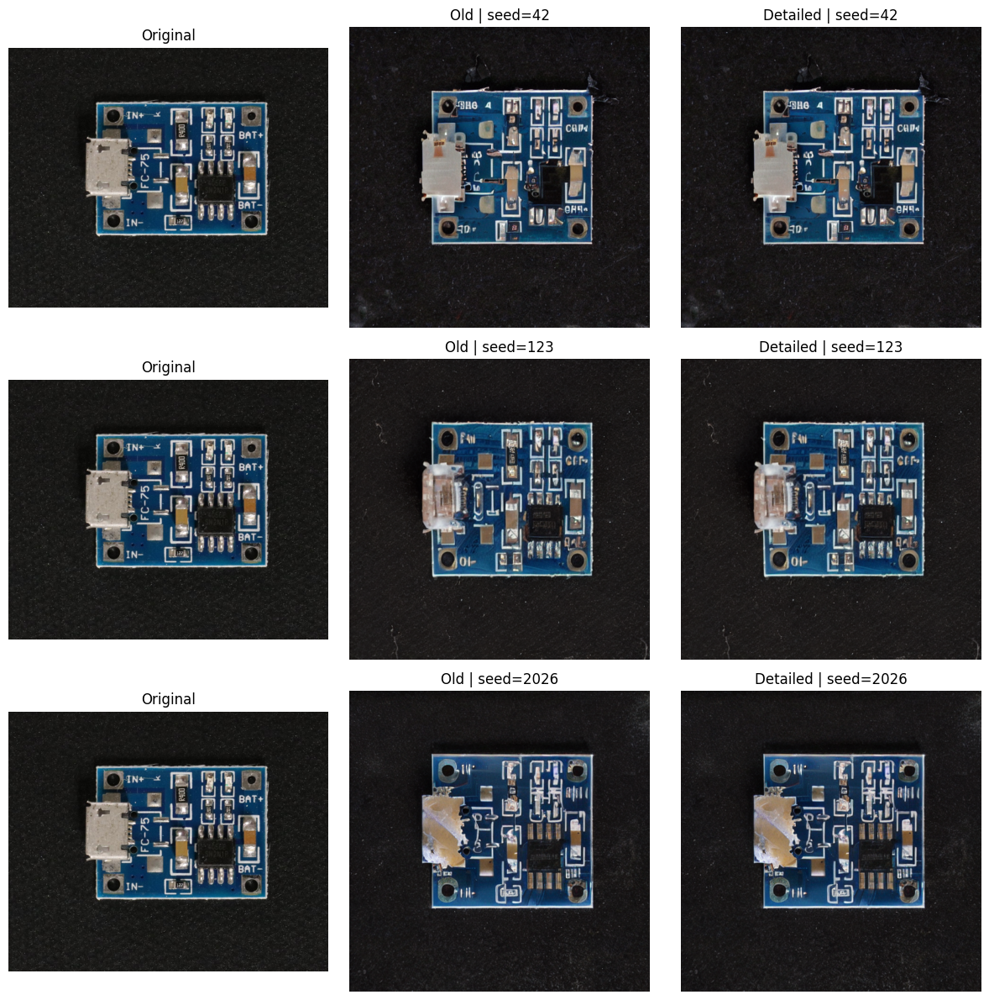

In [ ]:
exp2_fig, exp2_axes = plt.subplots(
    len(exp_seeds), 3, figsize=(12, 12), squeeze=False
)

for exp2_row, exp2_seed in enumerate(exp_seeds):
    print(f"상세 프롬프트 변경 실험: seed={exp2_seed}")

    exp2_image, _ = run_and_display(
        prompts=[prompt],
        controller=AttentionStore(),
        indices_to_alter=exp_indices,
        init_image=image_guidance.copy(),
        init_image_guidance_scale=0.3,
        mask_image=None,
        generator=torch.Generator(
            device=stable.device
        ).manual_seed(exp2_seed),
        run_standard_sd=False,
        display_output=False,
        scale_factor=50,
        normal_prompt=normal_prompt,
        detailed_prompt=exp2_detailed_prompt,
    )

    for exp2_col, (exp2_show, exp2_title) in enumerate([
        (image_guidance, "Original"),
        (exp2_old_images[exp2_row], f"Old | seed={exp2_seed}"),
        (exp2_image, f"Detailed | seed={exp2_seed}"),
    ]):
        exp2_axes[exp2_row, exp2_col].imshow(exp2_show)
        exp2_axes[exp2_row, exp2_col].set_title(exp2_title)
        exp2_axes[exp2_row, exp2_col].axis("off")

exp2_fig.tight_layout()
plt.show()

### 이미지의 픽셀 일치 여부 확인

두 결과가 매우 비슷해 보이므로 기존·변경 이미지를 픽셀 단위로 비교한다. 모든 픽셀이 같으면 `True`, 하나라도 다르면 `False`를 출력한다. 이 확인은 두 출력의 일치 여부를 구분한다.

In [ ]:
for i, seed in enumerate(exp_seeds):
    old = exp2_old_images[i]
    new = exp2_axes[i, 2].images[0].get_array()

    print(seed, "완전히 동일:", (old == new).all())

42 완전히 동일: False
123 완전히 동일: False
2026 완전히 동일: False


## 9. 추가 실험 2 결과 분석과 추가 실험 3 설계

### 상세 프롬프트 변경 결과

| 시드 | 기존 설명과 새 설명의 비교 |
|---|---|
| 42 | 부품 재구성과 기판 위쪽의 검은 흔적이 비슷하게 남았다. 뚜렷한 균열은 추가되지 않았다. |
| 123 | 커넥터와 부품 표현이 매우 유사했다. 기판을 가르는 균열이나 끊어진 구리 배선은 명확하지 않았다. |
| 2026 | 커넥터 부근의 황색 변화와 회로 변형이 비슷하게 나타났다. 균열 표현의 개선은 확인되지 않았다. |

픽셀 일치 검사에서는 세 시드 모두 `False`가 나왔다. 출력에 차이는 있지만, 상세 설명을 구체화한 효과가 원하는 균열 표현으로 이어지지는 않았다.

### 추가 실험 3 계획: 편집 마스크 적용

지금까지는 이미지 전체를 편집해 부품과 배경까지 변했다. PCB 중앙에 대각선 모양의 좁은 편집 영역을 지정하면 주변 구조를 유지하면서 해당 영역에 균열을 유도할 수 있는지 확인한다.

| 항목 | 설정 |
|---|---|
| 변경 조건 | 마스크 없음 / 대각선 마스크 적용 |
| 마스크 | 이미지 가로·세로의 32% 지점에서 68% 지점까지 잇는 선, 선폭은 짧은 변의 약 5% |
| 고정 조건 | 입력 PCB, 새 상세 설명, 조건값 0.3, 시드 42, 나머지 생성 설정 |
| 생성 수 | 두 조건에서 각각 1장, 총 2장 |
| 비교 기준 | 지정 영역의 균열, 마스크 밖 구조 보존, 편집 경계의 자연스러움 |

마스크 처리에서 사용하는 난수까지 맞추기 위해 각 호출 전에 전역 난수와 generator의 시드를 모두 42로 고정한다.

### 대각선 편집 영역 만들기

검은색 바탕의 마스크에 흰색 대각선을 그린다. 흰색은 편집 영역, 검은색은 원본을 유지하도록 지정하는 영역이다. `ImageDraw`만 추가로 불러오고 기존 이미지·모델·함수를 재사용한다.

In [ ]:
from PIL import ImageDraw

# 현재 PCB 이미지의 중앙을 대각선으로 가로지르는 편집 영역
exp3_w, exp3_h = image_guidance.size
exp3_mask = Image.new("L", image_guidance.size, 0)

ImageDraw.Draw(exp3_mask).line(
    [
        (int(exp3_w * 0.32), int(exp3_h * 0.32)),
        (int(exp3_w * 0.68), int(exp3_h * 0.68)),
    ],
    fill=255,
    width=max(1, int(min(exp3_w, exp3_h) * 0.05)),
)



### 마스크 유무에 따른 생성 비교

같은 조건에서 마스크가 없는 결과와 있는 결과를 생성한다. 원본, 마스크, 마스크 없는 결과, 마스크 적용 결과를 나란히 표시한다. 다음 실험에서는 마지막 결과를 0.3 기준 이미지로 재사용한다.

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

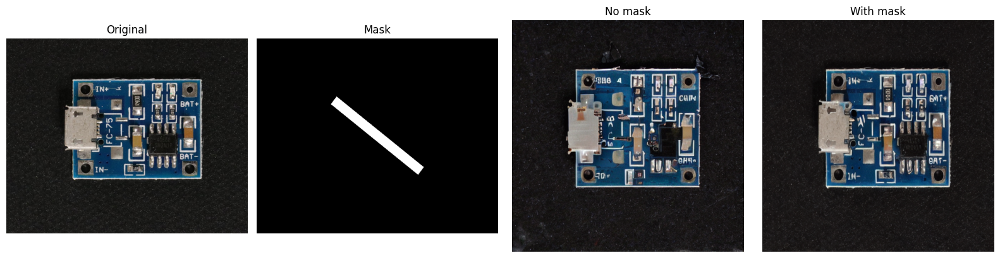

In [ ]:
exp3_fig, exp3_axes = plt.subplots(1, 4, figsize=(16, 4))

exp3_axes[0].imshow(image_guidance)
exp3_axes[0].set_title("Original")
exp3_axes[1].imshow(exp3_mask, cmap="gray")
exp3_axes[1].set_title("Mask")

for exp3_col, (exp3_title, exp3_current_mask) in enumerate([
    ("No mask", None),
    ("With mask", exp3_mask),
], start=2):
    # 마스크 처리 내부에서 사용하는 전역 난수도 동일하게 고정
    torch.manual_seed(42)

    exp3_image, _ = run_and_display(
        prompts=[prompt],
        controller=AttentionStore(),
        indices_to_alter=exp_indices,
        init_image=image_guidance.copy(),
        init_image_guidance_scale=0.3,
        mask_image=exp3_current_mask,
        generator=torch.Generator(
            device=stable.device
        ).manual_seed(42),
        run_standard_sd=False,
        display_output=False,
        scale_factor=50,
        normal_prompt=normal_prompt,
        detailed_prompt=exp2_detailed_prompt,
    )

    exp3_axes[exp3_col].imshow(exp3_image)
    exp3_axes[exp3_col].set_title(exp3_title)

for exp3_ax in exp3_axes:
    exp3_ax.axis("off")

exp3_fig.tight_layout()
plt.show()

## 10. 추가 실험 3 결과 분석과 추가 실험 4 설계

### 마스크 적용 결과

| 조건 | 관찰한 결과 |
|---|---|
| 마스크 없음 | 부품과 회로 형태가 달라지고 기판 위쪽 배경에 검은 흔적이 생겼다. 균열은 뚜렷하지 않았다. |
| 마스크 있음 | 기판 윤곽과 부품 배치가 원본에 더 가깝게 유지됐다. 다만 지정한 대각선 영역에도 뚜렷한 균열은 나타나지 않았다. |

시드 42의 비교에서는 마스크 적용으로 주변 구조의 변형을 줄일 수 있었다. 그러나 편집 범위를 제한하는 것만으로 균열이 생성되지는 않았다.

### 추가 실험 4 계획: 마스크 적용 상태에서 조건값 증가

마스크가 원본 보존을 개선했으므로, 이를 유지한 채 조건값을 높여 편집 영역의 변화가 커지는지 확인한다. 앞선 마스크 없는 0.5 결과에서 나타난 전체 구조 변형을 줄이면서 균열을 만들 수 있는지가 핵심이다.

| 항목 | 설정 |
|---|---|
| 변경 조건 | `init_image_guidance_scale`: 0.3 → 0.5 |
| 고정 조건 | 동일한 대각선 마스크, 입력 PCB, 새 상세 설명, 시드 42, 나머지 생성 설정 |
| 생성 수 | 0.5 결과 1장 추가. 직전 0.3 결과는 재사용 |
| 비교 기준 | 균열의 명확성, 마스크 밖 기판·부품의 보존, 편집 경계 |

### 조건값 0.5로 생성

전역 난수와 generator의 시드를 42로 맞추고, 기존 마스크와 상세 프롬프트를 그대로 전달한다. 조건값만 0.5로 높여 새 이미지를 생성한다.

In [ ]:
# 기존 마스크·시드·프롬프트를 유지하고 설정값만 0.3 → 0.5로 변경
torch.manual_seed(42)

exp4_image, _ = run_and_display(
    prompts=[prompt],
    controller=AttentionStore(),
    indices_to_alter=exp_indices,
    init_image=image_guidance.copy(),
    init_image_guidance_scale=0.5,
    mask_image=exp3_mask,
    generator=torch.Generator(device=stable.device).manual_seed(42),
    run_standard_sd=False,
    display_output=False,
    scale_factor=50,
    normal_prompt=normal_prompt,
    detailed_prompt=exp2_detailed_prompt,
)



  0%|          | 0/200 [00:00<?, ?it/s]

### 기존 0.3 결과와 비교

정상 원본, 직전 마스크 실험의 0.3 결과, 새로 생성한 0.5 결과를 나란히 표시한다. 기존 결과는 `exp3_axes`에서 가져온다.

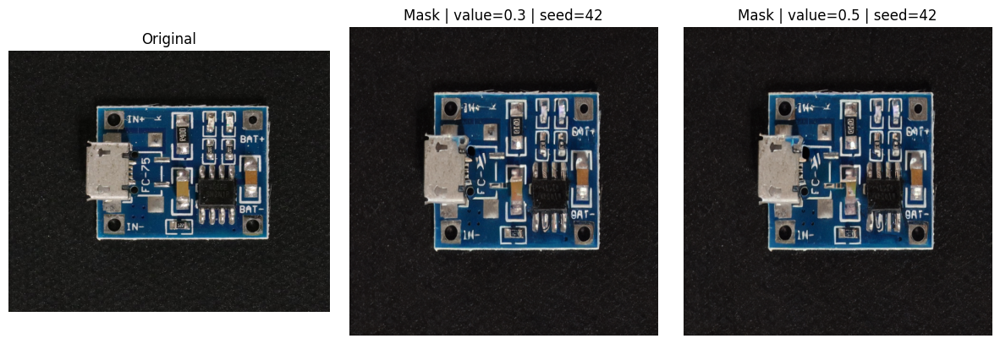

In [ ]:
exp4_fig, exp4_axes = plt.subplots(1, 3, figsize=(12, 4))

for exp4_ax, exp4_show, exp4_title in zip(
    exp4_axes,
    [
        image_guidance,
        exp3_axes[3].images[0].get_array(),
        exp4_image,
    ],
    ["Original", "Mask | value=0.3 | seed=42", "Mask | value=0.5 | seed=42"],
):
    exp4_ax.imshow(exp4_show)
    exp4_ax.set_title(exp4_title)
    exp4_ax.axis("off")

exp4_fig.tight_layout()
plt.show()

## 11. 마지막 실험 결과 분석

| 조건 | 관찰한 결과 |
|---|---|
| 마스크 적용·0.3 | 기판 윤곽과 부품 배치를 비교적 유지했지만 지정 영역에 뚜렷한 균열은 나타나지 않았다. |
| 마스크 적용·0.5 | 전체 구조는 비슷하게 유지됐고 일부 부품과 표면 표현이 달라졌다. 그러나 기판을 가르는 뚜렷한 균열은 나타나지 않았다. |

같은 마스크와 시드 42에서 조건값을 0.3에서 0.5로 높였지만 균열 표현은 개선되지 않았다. 일부 세부 표현의 차이는 목표한 균열로 해석하기 어려웠다. 마스크는 원본 구조를 보존하는 데 도움이 됐지만, 원하는 결함 형태를 생성하는 문제는 해결하지 못했다.

### 전체 실험의 성과

| 비교한 요소 | 확인한 내용 |
|---|---|
| 입력 이미지 조건값 | 마스크가 없을 때 값을 높이면 원본 구조의 변화가 커졌지만 균열이 명확해지지는 않았다. |
| 상세 프롬프트 | 기판과 끊어진 구리 배선을 구체적으로 설명해도 균열 표현의 개선은 확인되지 않았다. |
| 편집 마스크 | 주변 부품과 배경의 변형을 줄였지만, 지정 영역에 균열이 생성되지는 않았다. |
| 마스크 적용 후 조건값 증가 | 원본 구조는 비교적 유지됐으나, 값을 높이는 것만으로 균열을 만들지는 못했다. |

기본 예제와 네 차례의 추가 실험을 통해 생성 조건에 따른 출력 변화를 비교했다. 원본 보존과 결함 표현을 함께 평가했으며, 마스크 적용에서 원본 보존의 개선을 확인했다. 정상 PCB의 구조를 유지하면서 명확한 균열을 합성하는 목표에는 도달하지 못했다.

## 개인 회고 — KPT

### Keep
이전 실험 결과를 바탕으로 조건값, 상세 프롬프트, 마스크를 차례로 변경했다. 같은 시드의 결과를 비교하고 기존 이미지를 재사용해 불필요한 재생성을 줄였다. 이미지가 달라졌다는 사실과 목표한 균열이 생성됐다는 판단도 구분했다.

### Problem
초기에는 기존 코드와 실행 환경의 버전이 맞지 않아 import 오류가 반복됐다. Transformers·Diffusers·Hugging Face Hub의 호환성 문제에 더해 OpenAI CLIP 미설치와 Python 3.13에서 구형 IPython의 autoreload가 제거된 imp 모듈을 참조하는 문제도 있었다. 오류가 발생할 때마다 개별적으로 대응하면서 환경 정리에 시간이 들었다.

생성 실험에서는 마스크로 원본 보존을 개선했지만 명확한 PCB 균열은 얻지 못했다. 조건값이나 설명을 바꾸는 것만으로 원하는 결함 형태를 만들기는 어려웠다.

### Try
다음에는 Python 버전과 프로젝트 의존성을 먼저 확인하고, 호환되는 패키지 조합을 함께 고정하겠다. 모델을 불러오기 전에 핵심 import부터 확인해 환경 오류와 생성 코드 문제를 구분하겠다. 생성 실험은 다른 정상 PCB 이미지로도 확대하고, 실제 균열 사진을 참고해 결함 형태와 원본 보존을 함께 비교하겠다.